<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson13/Lesson13_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 13 — Integration and Accumulation: Adding Up Small Changes

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 4 — Calculus II\
**Lesson:** Lesson 13\
**Notebook type:** Teaching notebook

> *"A rate tells you how fast something changes. An integral tells you how much has changed in total."*

---

### From rates to totals

Lessons 9–12 started from a quantity and asked how fast it changes: the derivative. Much of neuroscience runs the other way. We know a **rate**, and want a **total**:

- a firing rate (spikes/s) over a stimulus → the expected **number of spikes**;
- a membrane current (pA) over time → the total **charge** delivered (fC);
- a hand velocity (cm/s) → the **displacement** of the hand (cm);
- a probability density (Lesson 17) → a **probability**.

The operation that turns a rate into a total is **integration**. This lesson builds it from sums of small pieces (Riemann sums), connects it to derivatives through the **Fundamental Theorem of Calculus**, and then does what data analysis needs: integrates **sampled** signals numerically, with attention to the sampling interval, the error, and irregular sampling. The mini-lab integrates hand velocity to recover hand position, and then integrates the velocity **decoded from motor cortex**, showing how a small, persistent decoding bias accumulates into a large position error: a real problem for brain–computer interfaces.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.integrate import cumulative_trapezoid

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-12.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-12.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def riemann(f, a, b, n, rule='left'):
    # Riemann sum of f over [a, b] with n equal pieces; rule = 'left', 'right' or 'mid'.
    h = (b - a) / n
    x = a + h * np.arange(n) + {'left': 0.0, 'right': h, 'mid': h / 2}[rule]
    return h * np.sum(f(x))

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: how many spikes does a stimulus evoke?**

After a brief stimulus, a sensory neuron's firing rate rises quickly and decays (an **alpha-function** response, as for a synaptic conductance in Lesson 11):

$$r(t) = r_0 + A\,\frac{t}{\tau}\,e^{1 - t/\tau}\qquad (t \ge 0,\ \text{in ms};\ r\ \text{in spikes/s}),$$

with baseline $r_0 = 5$ spikes/s, peak increase $A = 60$ spikes/s and $\tau = 40$ ms. How many spikes, on average, does the neuron fire in the 300 ms after the stimulus?

The rate changes all the time, so "rate × time" does not apply directly. But over a **short** interval $\Delta t$ the rate is nearly constant, and the expected count in that interval is about $r(t)\,\Delta t$. Adding these pieces gives the expected total. Below, simulated spike trains (an inhomogeneous Poisson process, Lesson 18) confirm the answer.

sum of r(t) dt over 1 ms pieces: 7.993 spikes;  exact integral: 7.993;  mean of 2000 simulated trials: 7.939


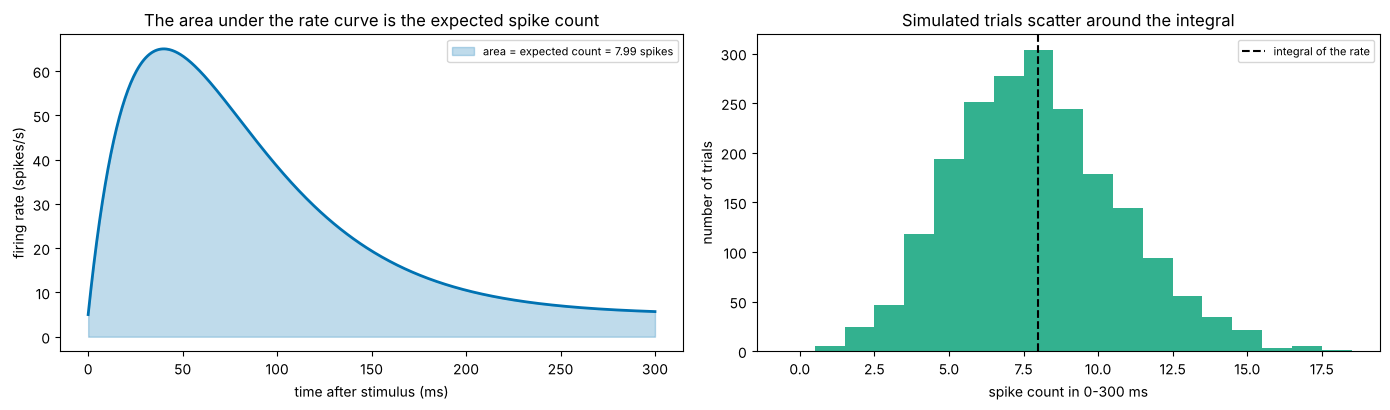

In [3]:
r0, A_r, tau_r = 5.0, 60.0, 40.0
def rate(t_ms):
    return r0 + A_r * (t_ms / tau_r) * np.exp(1 - t_ms / tau_r)       # spikes/s

T_win = 300.0                                                      # ms
dt_ms = 1.0
t_ms = np.arange(0, T_win, dt_ms)                                  # (300,) bin starts, ms
expected_sum = np.sum(rate(t_ms) * dt_ms / 1000)                    # sum of r(t) dt, with dt converted to seconds
exact = r0 * T_win / 1000 + A_r * np.e * tau_r / 1000 * (1 - (1 + T_win / tau_r) * np.exp(-T_win / tau_r))
counts = RNG.poisson(rate(t_ms) * dt_ms / 1000, size=(2000, t_ms.size)).sum(axis=1)   # (2000,) spike counts in 2000 simulated trials
print(f"sum of r(t) dt over 1 ms pieces: {expected_sum:.3f} spikes;  exact integral: {exact:.3f};  mean of 2000 simulated trials: {counts.mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
tt = np.linspace(0, T_win, 601)
axes[0].fill_between(tt, 0, rate(tt), color=PALETTE[0], alpha=0.25, label=f'area = expected count = {exact:.2f} spikes')
axes[0].plot(tt, rate(tt), color=PALETTE[0], lw=2)
axes[0].set_xlabel('time after stimulus (ms)'); axes[0].set_ylabel('firing rate (spikes/s)'); axes[0].set_title('The area under the rate curve is the expected spike count'); axes[0].legend(fontsize=8)
axes[1].hist(counts, bins=np.arange(-0.5, counts.max() + 1.5), color=PALETTE[2], alpha=0.8)
axes[1].axvline(exact, color='black', ls='--', label='integral of the rate')
axes[1].set_xlabel('spike count in 0-300 ms'); axes[1].set_ylabel('number of trials'); axes[1].set_title('Simulated trials scatter around the integral'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Note the **units**: spikes/s times ms is not a count until the ms are converted to seconds. Every integral carries the units of the integrand **times** the units of the variable of integration.

# **Part 1: Antiderivatives and the Definite Integral**

### Antiderivatives
A function $F$ is an **antiderivative** of $f$ if $F'(x) = f(x)$. Antiderivatives are written $\int f(x)\,dx = F(x) + C$: they are determined only up to an added constant $C$, because constants have zero derivative. Reading Lesson 9's derivative table backwards:

| $f(x)$ | $\int f(x)\,dx$ |
|---|---|
| $x^n$ ($n \ne -1$) | $\frac{x^{n+1}}{n+1} + C$ |
| $1/x$ | $\ln\lvert x\rvert + C$ |
| $e^{kx}$ | $\frac1k e^{kx} + C$ |
| $\sin(\omega x)$, $\cos(\omega x)$ | $-\frac1\omega\cos(\omega x) + C$, $\frac1\omega\sin(\omega x) + C$ |
| $\sigma(x)$ (sigmoid) | $\ln(1 + e^x) + C$ (softplus) |

Linear combinations integrate term by term. Some antiderivatives need more technique (substitution, integration by parts; see Further reading); many, such as $\int e^{-x^2}dx$, have no formula at all, which is one reason numerical integration (Part 4) matters.

### The definite integral
The **definite integral** $\int_a^b f(x)\,dx$ is a number: the **signed area** between the graph of $f$ and the $x$-axis from $a$ to $b$ (area above the axis counts positive, below negative). It is defined as the limit of sums of thin rectangles (Part 2). Its properties:
- **linearity**: $\int_a^b(\alpha f + \beta g) = \alpha\int_a^b f + \beta\int_a^b g$;
- **additivity**: $\int_a^b f + \int_b^c f = \int_a^c f$;
- **orientation**: $\int_b^a f = -\int_a^b f$;
- **units**: [units of $f$] × [units of $x$].

The link between the two ideas, proved in Part 3, is that **if $F$ is any antiderivative of $f$, then $\int_a^b f(x)\,dx = F(b) - F(a)$**.

### Neural examples
- **Exponential decay** of a synaptic current $I(t) = I_0e^{-t/\tau}$: total charge $\int_0^\infty I_0e^{-t/\tau}dt = I_0\tau$. With $I_0 = 100$ pA and $\tau = 5$ ms, $Q = 500$ pA·ms $= 500$ fC.
- **Alpha function** $g(t) = g_{\max}\frac{t}{\tau}e^{1 - t/\tau}$: $\int_0^\infty g\,dt = g_{\max}\,e\,\tau$ (it has the same area as a rectangle of height $g_{\max}$ and width $e\tau \approx 2.72\tau$).
- **Constant rate** $r$ for time $T$: expected count $rT$, the simplest integral of all.

exponential current: formula I0 tau = 500.0 fC;  numerical (scipy quad) 500.0000 fC
alpha conductance:   formula g_max e tau = 16.3097 nS ms;  numerical 16.3097 nS ms


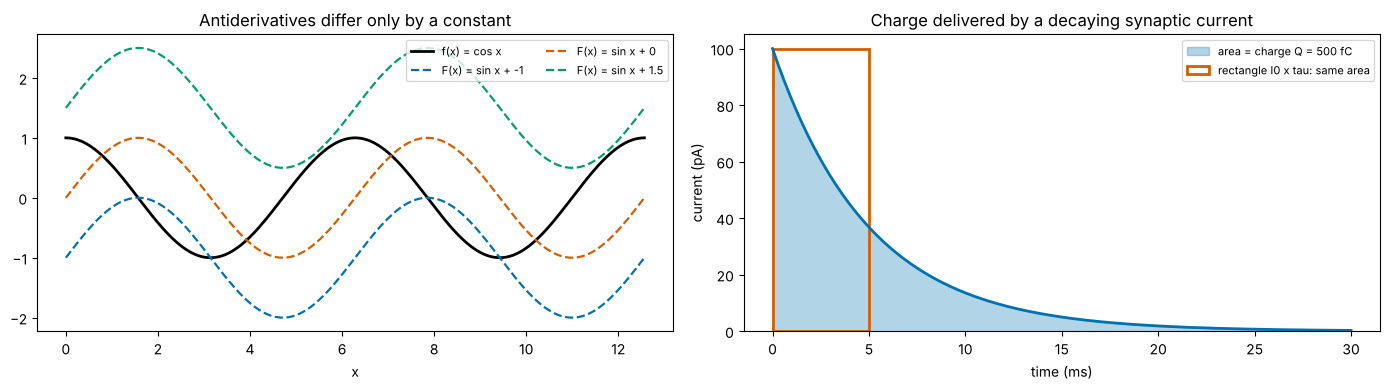

In [4]:
from scipy.integrate import quad
I0, tau_I = 100.0, 5.0                                             # pA, ms
Q_formula = I0 * tau_I                                             # pA * ms = fC
Q_quad, _ = quad(lambda t: I0 * np.exp(-t / tau_I), 0, np.inf)
g_max, tau_g = 2.0, 3.0                                            # nS, ms
area_alpha, _ = quad(lambda t: g_max * (t / tau_g) * np.exp(1 - t / tau_g), 0, np.inf)
print(f"exponential current: formula I0 tau = {Q_formula:.1f} fC;  numerical (scipy quad) {Q_quad:.4f} fC")
print(f"alpha conductance:   formula g_max e tau = {g_max * np.e * tau_g:.4f} nS ms;  numerical {area_alpha:.4f} nS ms")

# Antiderivatives are fixed only up to a constant: three antiderivatives of cos(x) differ by vertical shifts.
xs = np.linspace(0, 4 * np.pi, 400)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(xs, np.cos(xs), color='black', lw=2, label='f(x) = cos x')
for Cc, colour in zip([-1, 0, 1.5], PALETTE):
    axes[0].plot(xs, np.sin(xs) + Cc, color=colour, lw=1.6, ls='--', label=f'F(x) = sin x + {Cc}')
axes[0].set_xlabel('x'); axes[0].set_title('Antiderivatives differ only by a constant'); axes[0].legend(fontsize=8, ncol=2)
tI = np.linspace(0, 30, 300)
axes[1].fill_between(tI, 0, I0 * np.exp(-tI / tau_I), color=PALETTE[0], alpha=0.3, label='area = charge Q = 500 fC')
axes[1].plot(tI, I0 * np.exp(-tI / tau_I), color=PALETTE[0], lw=2)
axes[1].bar(tau_I / 2, I0, width=tau_I, color='none', edgecolor=PALETTE[1], lw=2, label='rectangle I0 x tau: same area')
axes[1].set_xlabel('time (ms)'); axes[1].set_ylabel('current (pA)'); axes[1].set_title('Charge delivered by a decaying synaptic current'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# **Part 2: Riemann Sums, Signed Area and Average Value**

Split $[a, b]$ into $n$ pieces of width $h = (b - a)/n$, choose a point $x_i^\star$ in each piece, and add the areas of the rectangles:

$$S_n = \sum_{i=0}^{n-1} f(x_i^\star)\,h .$$

Choosing $x_i^\star$ at the **left** end, the **right** end or the **midpoint** of each piece gives the left, right and midpoint sums. For a continuous $f$, all of them approach the same number as $n \to \infty$: that limit **is** the definite integral. Riemann sums are therefore both the **definition** of the integral and the simplest **way to compute** it.

**Signed area.** Where $f < 0$ the rectangles have negative height. A membrane current that is inward (negative, by convention) for part of the time and outward for the rest delivers a **net** charge equal to the signed area, which can be much smaller than the total area $\int|f|$.

**Average value.** The average of $f$ over $[a, b]$ is

$$\bar f = \frac{1}{b - a}\int_a^b f(x)\,dx,$$

the height of the rectangle with the same width and the same area. It is the continuous version of the mean of $n$ equally spaced samples: $\frac1n\sum f(x_i) = \frac{1}{b - a}\sum f(x_i)\,h$. A neuron's **mean firing rate** over a trial is the average value of its rate; the expected count is that average times the duration.

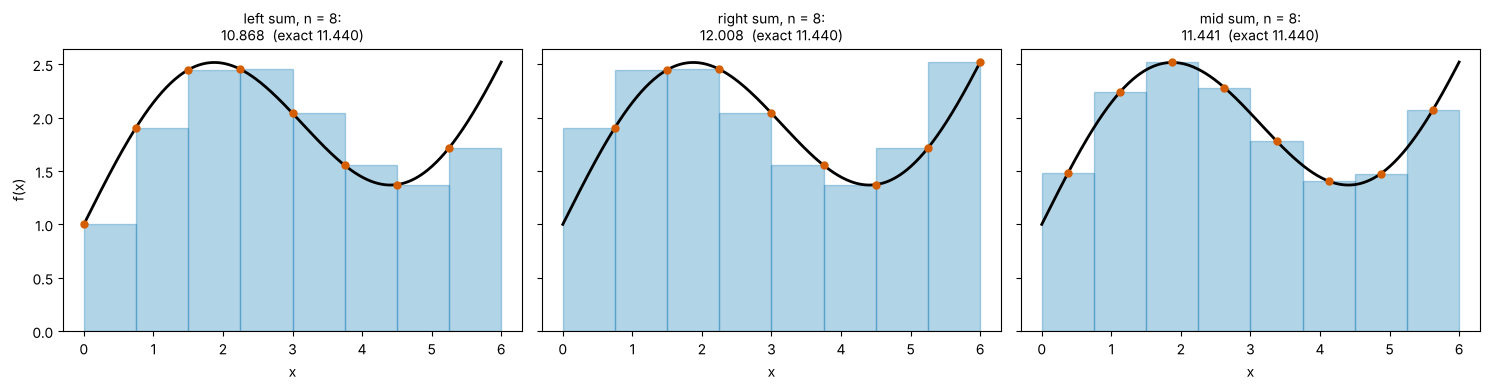

     n        left       right    midpoint
     4   -1.15e+00    1.13e+00    3.99e-03   (errors)
    16   -2.86e-01    2.85e-01    2.34e-04   (errors)
    64   -7.13e-02    7.12e-02    1.46e-05   (errors)
   256   -1.78e-02    1.78e-02    9.12e-07   (errors)
  1024   -4.45e-03    4.45e-03    5.70e-08   (errors)


In [5]:
f_demo = lambda x: 1 + np.sin(x) + 0.3 * x                          # a smooth function on [0, 6]
a_d, b_d = 0.0, 6.0
I_exact = (b_d - a_d) + (1 - np.cos(b_d)) + 0.15 * (b_d**2 - a_d**2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
xx = np.linspace(a_d, b_d, 400)
for ax, rule in zip(axes, ['left', 'right', 'mid']):
    n = 8; h = (b_d - a_d) / n
    xr = a_d + h * np.arange(n) + {'left': 0.0, 'right': h, 'mid': h / 2}[rule]
    ax.bar(a_d + h * np.arange(n), f_demo(xr), width=h, align='edge', color=PALETTE[0], alpha=0.3, edgecolor=PALETTE[0])
    ax.plot(xx, f_demo(xx), color='black', lw=2)
    ax.plot(xr, f_demo(xr), 'o', color=PALETTE[1], ms=5)
    ax.set_title(f'{rule} sum, n = 8:\n{riemann(f_demo, a_d, b_d, 8, rule):.3f}  (exact {I_exact:.3f})', fontsize=10); ax.set_xlabel('x')
axes[0].set_ylabel('f(x)')
plt.tight_layout(); plt.show()

print(f"{'n':>6}{'left':>12}{'right':>12}{'midpoint':>12}")
for n in [4, 16, 64, 256, 1024]:
    print(f"{n:>6}" + ''.join(f"{riemann(f_demo, a_d, b_d, n, r) - I_exact:>12.2e}" for r in ['left', 'right', 'mid']) + "   (errors)")

The left and right sums err in opposite directions by about the same amount, and their errors shrink in proportion to $1/n$ (four times more pieces, four times smaller error). The midpoint error shrinks like $1/n^2$ (four times more pieces, **sixteen** times smaller): placing each sample in the middle cancels most of the error. Part 4 explains why.

#### Interactive version: more and more rectangles

In [6]:
ns = [2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 100]
def rect_xy(n):
    h = (b_d - a_d) / n
    xl = a_d + h * np.arange(n)
    y = f_demo(xl + h / 2)
    X, Y = [], []
    for x0, y0 in zip(xl, y):
        X += [x0, x0, x0 + h, x0 + h, None]; Y += [0, y0, y0, 0, None]
    return X, Y
X0, Y0 = rect_xy(ns[0])
fig_r = go.Figure([go.Scatter(x=X0, y=Y0, mode='lines', fill='toself', line=dict(color=PALETTE[0], width=1), fillcolor='rgba(0,114,178,0.25)', name='midpoint rectangles'),
                   go.Scatter(x=xx, y=np.round(f_demo(xx), 4), mode='lines', line=dict(color='black', width=3), name='f(x)')])
fig_r.frames = [go.Frame(name=str(k), traces=[0], data=[go.Scatter(x=rect_xy(n)[0], y=rect_xy(n)[1])],
                         layout=go.Layout(title=f'n = {n}: midpoint sum {riemann(f_demo, a_d, b_d, n, "mid"):.5f}, exact {I_exact:.5f}')) for k, n in enumerate(ns)]
buttons, sliders = play_pause_and_slider(ns, prefix='n = ', duration=500)
fig_r.update_layout(title=fig_r.frames[0].layout.title.text, xaxis_title='x', yaxis_title='f(x)', template='plotly_white',
                    width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_r.show(config=PLOTLY_CONFIG)

### Signed area and average value: a membrane current
A simulated membrane current during an action potential: a brief **inward** (negative) sodium current followed by a longer **outward** (positive) potassium current.

inward charge -156.1 fC;  outward 170.2 fC;  net (signed area) 14.1 fC;  total |area| 326.3 fC
average current over 6 ms: 2.35 pA


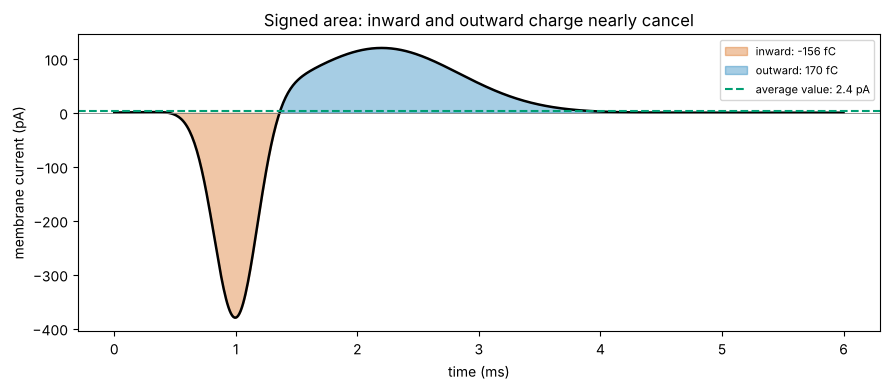

In [7]:
t_ap = np.linspace(0, 6, 601)                                       # ms
I_ap = -400 * np.exp(-((t_ap - 1.0) / 0.25)**2) + 120 * np.exp(-((t_ap - 2.2) / 0.9)**2)   # pA; negative = inward
net = np.trapezoid(I_ap, t_ap)                                       # signed area, pA ms = fC
gross = np.trapezoid(np.abs(I_ap), t_ap)
inward = np.trapezoid(np.minimum(I_ap, 0), t_ap)
print(f"inward charge {inward:.1f} fC;  outward {net - inward:.1f} fC;  net (signed area) {net:.1f} fC;  total |area| {gross:.1f} fC")
print(f"average current over 6 ms: {net / 6:.2f} pA")
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(t_ap, 0, I_ap, where=I_ap < 0, color=PALETTE[1], alpha=0.35, label=f'inward: {inward:.0f} fC')
ax.fill_between(t_ap, 0, I_ap, where=I_ap > 0, color=PALETTE[0], alpha=0.35, label=f'outward: {net - inward:.0f} fC')
ax.plot(t_ap, I_ap, color='black', lw=1.8)
ax.axhline(net / 6, color=PALETTE[2], ls='--', label=f'average value: {net / 6:.1f} pA')
ax.axhline(0, color='grey', lw=0.6)
ax.set_xlabel('time (ms)'); ax.set_ylabel('membrane current (pA)'); ax.set_title('Signed area: inward and outward charge nearly cancel'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# **Part 3: The Fundamental Theorem — Accumulation and Rate**

Define the **accumulation function** that collects area from a fixed start $a$ up to a moving end $x$:

$$A(x) = \int_a^x f(s)\,ds .$$

> **Fundamental Theorem of Calculus.**
> **(1)** If $f$ is continuous, then $A'(x) = f(x)$: the rate at which area accumulates is the height of the curve at the moving edge.
> **(2)** If $F$ is any antiderivative of $f$, then $\int_a^b f(x)\,dx = F(b) - F(a)$.

**Why (1) holds.** Moving the edge from $x$ to $x + h$ adds a thin strip of width $h$ and height about $f(x)$: $A(x + h) - A(x) \approx f(x)\,h$. Dividing by $h$ and letting $h \to 0$ gives $A'(x) = f(x)$.

**Why (2) follows.** $A$ and $F$ are both antiderivatives of $f$, so they differ by a constant: $A(x) = F(x) - F(a)$ (the constant is fixed by $A(a) = 0$). Setting $x = b$ gives the formula.

**In words: integration and differentiation undo each other.** Integrating a rate gives the accumulated total; differentiating the total gives back the rate. For data the discrete versions are `np.cumsum` (or `cumulative_trapezoid`) and `np.diff`:

| Rate | Accumulated quantity | Relation |
|---|---|---|
| velocity $v(t)$ (cm/s) | position $x(t)$ (cm) | $x(t) = x(0) + \int_0^t v\,ds$ |
| firing rate $r(t)$ (spikes/s) | expected spike count $N(t)$ | $N(t) = \int_0^t r\,ds$ |
| current $I(t)$ (pA) | charge $Q(t)$ (fC) | $Q(t) = \int_0^t I\,ds$; and $C\,dV/dt = I$ gives $V$ (Lesson 21) |
| gradient $-\eta L'(\theta)$ (Lesson 12) | parameter change | $\theta_k = \theta_0 - \sum_j \eta L'(\theta_j)$ |

accumulated count at 300 ms: 7.9932 (exact 7.9932);  largest |d/dt of accumulation - rate| = 2.03e-01 spikes/s


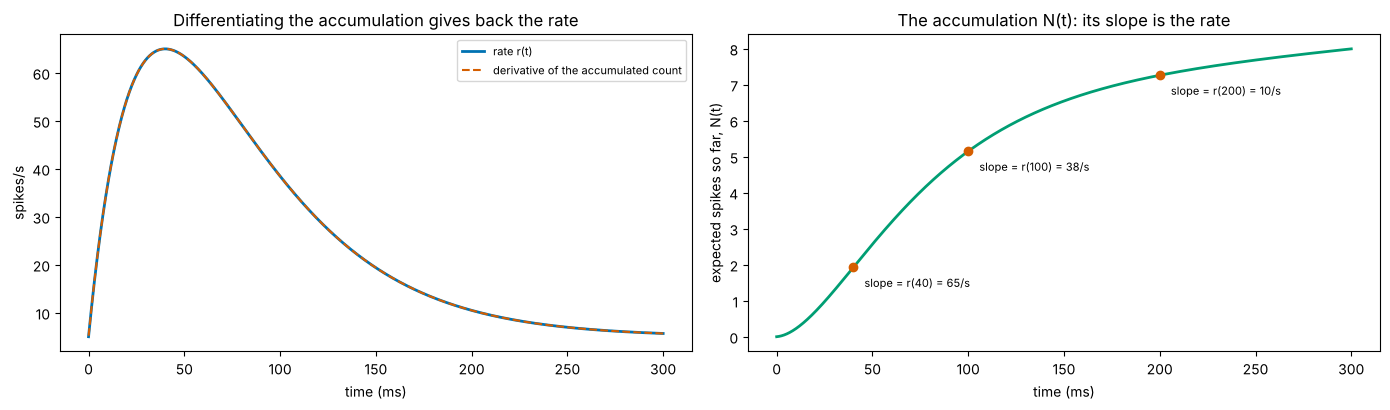

In [8]:
tt_f = np.linspace(0, T_win, 3001)                                  # ms, step 0.1 ms
N_acc = cumulative_trapezoid(rate(tt_f) / 1000, tt_f, initial=0)    # (3001,) expected count accumulated up to t
rate_back = np.gradient(N_acc, tt_f) * 1000                         # differentiate the accumulation: back to spikes/s
print(f"accumulated count at 300 ms: {N_acc[-1]:.4f} (exact {exact:.4f});  largest |d/dt of accumulation - rate| = {np.max(np.abs(rate_back - rate(tt_f))):.2e} spikes/s")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(tt_f, rate(tt_f), color=PALETTE[0], lw=2, label='rate r(t)')
axes[0].plot(tt_f, rate_back, color=PALETTE[1], lw=1.5, ls='--', label='derivative of the accumulated count')
axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel('spikes/s'); axes[0].set_title('Differentiating the accumulation gives back the rate'); axes[0].legend(fontsize=8)
axes[1].plot(tt_f, N_acc, color=PALETTE[2], lw=2)
for t_mark in [40, 100, 200]:
    i = np.searchsorted(tt_f, t_mark)
    axes[1].plot(t_mark, N_acc[i], 'o', color=PALETTE[1])
    axes[1].annotate(f'slope = r({t_mark}) = {rate(t_mark):.0f}/s', (t_mark, N_acc[i]), textcoords='offset points', xytext=(8, -14), fontsize=8)
axes[1].set_xlabel('time (ms)'); axes[1].set_ylabel('expected spikes so far, N(t)'); axes[1].set_title('The accumulation N(t): its slope is the rate')
plt.tight_layout(); plt.show()

#### Interactive version: sweep the upper limit

In [9]:
ends = np.arange(10, 301, 10)
fig_a = go.Figure([go.Scatter(x=tt_f, y=np.round(rate(tt_f), 3), mode='lines', line=dict(color='black', width=2), name='rate r(t)'),
                   go.Scatter(x=tt_f[:101], y=np.round(rate(tt_f[:101]), 3), mode='lines', fill='tozeroy', line=dict(color=PALETTE[0], width=1), name='area so far')])
fig_a.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=tt_f[tt_f <= e][::5], y=np.round(rate(tt_f[tt_f <= e][::5]), 3))],
                         layout=go.Layout(title=f'N({e} ms) = area so far = {N_acc[np.searchsorted(tt_f, e)]:.3f} spikes;  slope r({e}) = {rate(e):.1f} spikes/s'))
                for k, e in enumerate(ends)]
buttons, sliders = play_pause_and_slider(list(ends), prefix='upper limit (ms) = ', duration=250)
fig_a.update_layout(title=fig_a.frames[0].layout.title.text, xaxis_title='time (ms)', yaxis_title='spikes/s', template='plotly_white',
                    width=850, height=460, updatemenus=buttons, sliders=sliders)
fig_a.show(config=PLOTLY_CONFIG)

# **Part 4: Numerical Quadrature, Sampling Interval, Error and Irregular Sampling**

Data arrive as **samples** $f_0, f_1, \dots, f_n$ at times $t_0 < t_1 < \dots < t_n$. Numerical integration (**quadrature**) estimates $\int f$ from them.

| Rule | Formula (equal spacing $h$) | Error | Idea |
|---|---|---|---|
| left / right Riemann | $h\sum f_i$ (omitting the last / first sample) | $\propto h$ | flat pieces |
| midpoint | $h\sum f(t_i + h/2)$ | $\propto h^2$ | flat pieces, sampled in the middle |
| **trapezoid** | $h\big(\tfrac12f_0 + f_1 + \dots + f_{n-1} + \tfrac12f_n\big)$ | $\propto h^2$ | straight-line pieces |
| Simpson | $\frac h3(f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + f_n)$ | $\propto h^4$ | parabolic pieces |

The error orders come from Taylor approximation (Lesson 11): a flat piece misses the slope term ($\propto h^2$ per piece, $n \propto 1/h$ pieces, so $\propto h$ in total); a straight piece misses only the curvature term ($\propto h^3$ per piece, $\propto h^2$ in total), and its error is about $-\frac{(b - a)h^2}{12}\overline{f''}$.

**The sampling interval limits the accuracy, not the rule.** With recorded data you cannot shrink $h$: it is fixed by the acquisition. Higher-order rules help only if the signal is smooth **on the scale of $h$**. If the signal changes substantially between samples, for example an oscillation faster than half the sampling rate (the Nyquist limit), no rule can recover the integral: the samples simply do not contain the information (**aliasing**).

**Noise.** Integration **averages** noise: independent sample errors of SD $\sigma$ give an integral error of SD about $\sigma h\sqrt n = \sigma\sqrt{h(b - a)}$, growing only like the square root of the duration. A **bias** (a constant offset $\delta$), however, accumulates in proportion to the duration: $\delta(b - a)$. This difference returns in the mini-lab.

**Irregular sampling.** Missing samples, event times or jittered clocks give unequal spacings $h_i = t_{i+1} - t_i$. The trapezoid rule generalises directly, $\sum_i \frac{f_i + f_{i+1}}{2}h_i$ (`np.trapezoid(f, t)`), while formulas that assume equal spacing are then simply wrong.

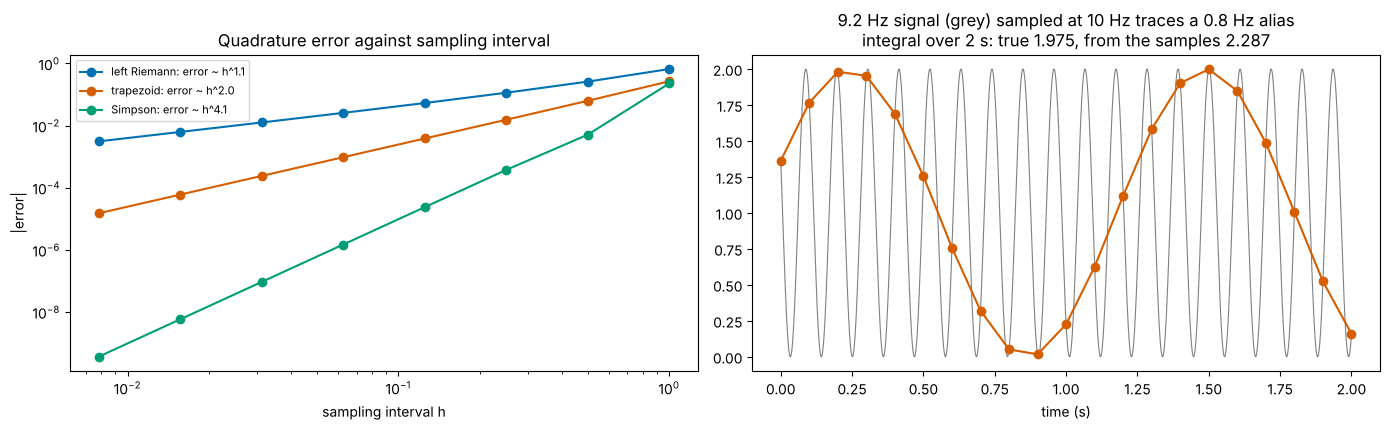

In [10]:
from scipy.integrate import simpson
f_q = lambda t: np.exp(-t) * np.sin(3 * t) + 1 + 0.2 * t            # a smooth test signal on [0, 4] (f(4) - f(0) is not 0)
I_q, _ = quad(f_q, 0, 4)
ns_q = np.array([4, 8, 16, 32, 64, 128, 256, 512])
errs = {'left Riemann': [], 'trapezoid': [], 'Simpson': []}
for n in ns_q:
    tq = np.linspace(0, 4, n + 1); fq = f_q(tq); h = 4 / n
    errs['left Riemann'].append(abs(h * fq[:-1].sum() - I_q))
    errs['trapezoid'].append(abs(np.trapezoid(fq, tq) - I_q))
    errs['Simpson'].append(abs(simpson(fq, x=tq) - I_q))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for (name, e), colour in zip(errs.items(), PALETTE):
    slope = np.polyfit(np.log(4 / ns_q), np.log(e), 1)[0]
    axes[0].loglog(4 / ns_q, e, 'o-', color=colour, label=f'{name}: error ~ h^{slope:.1f}')
axes[0].set_xlabel('sampling interval h'); axes[0].set_ylabel('|error|'); axes[0].set_title('Quadrature error against sampling interval'); axes[0].legend(fontsize=8)

# Aliasing: integrating a 9.2 Hz oscillation sampled every 100 ms (10 Hz sampling, Nyquist 5 Hz).
t_fine = np.linspace(0, 2, 4001)
sig = lambda t: 1 + np.cos(2 * np.pi * 9.2 * t + 1.2)
t_s = np.arange(0, 2.0001, 0.1)
axes[1].plot(t_fine, sig(t_fine), color='grey', lw=0.8, label=f'9.2 Hz signal: integral over 2 s = {np.trapezoid(sig(t_fine), t_fine):.3f}')
axes[1].plot(t_s, sig(t_s), 'o-', color=PALETTE[1], label=f'sampled every 100 ms: trapezoid = {np.trapezoid(sig(t_s), t_s):.3f}')
axes[1].set_xlabel('time (s)')
axes[1].set_title(f'9.2 Hz signal (grey) sampled at 10 Hz traces a 0.8 Hz alias\nintegral over 2 s: true {np.trapezoid(sig(t_fine), t_fine):.3f}, from the samples {np.trapezoid(sig(t_s), t_s):.3f}')
plt.tight_layout(); plt.show()

The left panel confirms the error orders: left Riemann $\propto h$, trapezoid $\propto h^2$, Simpson $\propto h^4$. In the right panel the 9.2 Hz signal, sampled at 10 Hz, looks like a slow 0.8 Hz wave ($10 - 9.2 = 0.8$): the samples' integral is about 16% too large, and no quadrature rule applied to these samples can tell.

### Noise against bias, and irregular samples

In [11]:
rng_n = np.random.default_rng(1)
durations = np.array([1, 4, 16, 64, 256])                             # s
h_n, sigma_n, bias_n = 0.05, 2.0, 0.1                                  # 50 ms samples; noise SD 2 cm/s; bias 0.1 cm/s
sd_noise, err_bias = [], []
for D in durations:
    n = int(D / h_n)
    noise_ints = (rng_n.normal(0, sigma_n, (400, n)) * h_n).sum(axis=1)    # (400,) integrals of pure noise
    sd_noise.append(noise_ints.std())
    err_bias.append(bias_n * D)
print("duration (s):            ", durations)
print("SD of integrated noise:  ", np.round(sd_noise, 3), "  predicted sigma sqrt(h D):", np.round(sigma_n * np.sqrt(h_n * durations), 3))
print("error from a 0.1 bias:   ", np.round(err_bias, 3))

# Irregular sampling: keep a random 40% of samples of the alpha-function rate and integrate with the true times.
rng_i = np.random.default_rng(2)
t_reg = np.arange(0, 300.1, 5.0)                                       # ms, regular 5 ms samples
keep = np.sort(np.r_[0, rng_i.choice(np.arange(1, t_reg.size - 1), int(0.4 * t_reg.size), replace=False), t_reg.size - 1])
t_irr = t_reg[keep]
print(f"\nexact {exact:.4f} spikes;  regular 5 ms trapezoid {np.trapezoid(rate(t_reg) / 1000, t_reg):.4f};  "
      f"irregular trapezoid with true times {np.trapezoid(rate(t_irr) / 1000, t_irr):.4f};  irregular, wrongly assuming 5 ms spacing {np.trapezoid(rate(t_irr) / 1000, dx=5.0):.4f}")

duration (s):             [  1   4  16  64 256]
SD of integrated noise:   [0.434 0.829 1.785 3.681 7.251]   predicted sigma sqrt(h D): [0.447 0.894 1.789 3.578 7.155]
error from a 0.1 bias:    [ 0.1  0.4  1.6  6.4 25.6]

exact 7.9932 spikes;  regular 5 ms trapezoid 7.9847;  irregular trapezoid with true times 7.9603;  irregular, wrongly assuming 5 ms spacing 4.0287


Integrated noise grows like $\sqrt{\text{duration}}$, while a bias of only 0.1 cm/s, invisible next to noise of SD 2 cm/s, overtakes it after about 20 s (where $0.1D = 2\sqrt{0.05D}$) and keeps growing linearly. With irregular samples the trapezoid rule using the **true** times is accurate; assuming the spacing is regular discards the missing time and badly underestimates the integral.

# **Part 5: Mini-Lab — From Hand Velocity to Hand Position, and Why Decoders Drift**

The motor-cortex data set ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)) contains both the hand **velocity** and the hand **position**, sampled every 50 ms. By the Fundamental Theorem, integrating the velocity from a known start should give the position:

$$\mathbf{p}(t) = \mathbf{p}(t_0) + \int_{t_0}^{t}\mathbf{v}(s)\,ds .$$

**Plan.**
1. Integrate the recorded velocity and compare with the recorded position.
2. Coarsen the sampling interval and drop samples at random: how does the error change, and what does irregular sampling require?
3. Integrate the velocity **decoded from 170 neurons** (the linear decoder of Lesson 5) and watch the position error grow with time.

duration 776.8 s; sampling interval 49.5-50.5 ms
after  1 min: |integrated - recorded position| = 0.35 cm
after  5 min: |integrated - recorded position| = 1.60 cm
after 10 min: |integrated - recorded position| = 0.59 cm


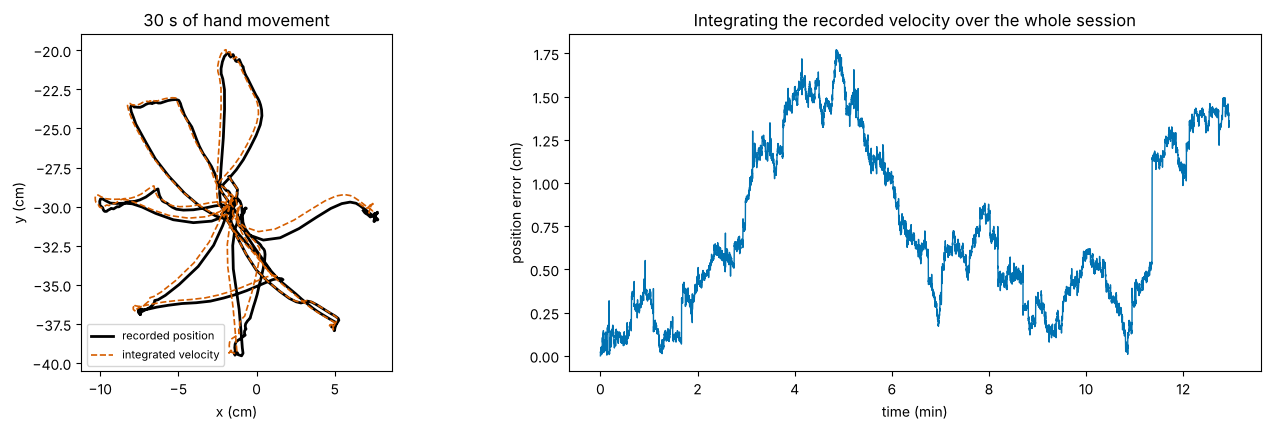

In [12]:
import os, urllib.request
from scipy.io import loadmat
from scipy.ndimage import gaussian_filter1d

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
time_s = m1['time'].ravel()                                         # (15536,) s
pos = m1['handPos'][:2].T * 100                                      # (15536, 2) hand position, cm
vel = m1['handVel'][:2].T * 100                                      # (15536, 2) hand velocity, cm/s
dts = np.diff(time_s)
print(f"duration {time_s[-1] - time_s[0]:.1f} s; sampling interval {dts.min() * 1000:.1f}-{dts.max() * 1000:.1f} ms")

pos_int = pos[0] + cumulative_trapezoid(vel, time_s, axis=0, initial=0)   # (15536, 2) position from integrated velocity
err_int = np.linalg.norm(pos_int - pos, axis=1)
for minutes in [1, 5, 10]:
    i = np.searchsorted(time_s - time_s[0], 60 * minutes)
    print(f"after {minutes:2d} min: |integrated - recorded position| = {err_int[i]:.2f} cm")

w0, W = 4000, 600                                                    # a 30 s stretch for plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
seg = slice(w0, w0 + W)
pi_seg = pos[w0] + cumulative_trapezoid(vel[seg], time_s[seg], axis=0, initial=0)
axes[0].plot(pos[seg, 0], pos[seg, 1], color='black', lw=2, label='recorded position')
axes[0].plot(pi_seg[:, 0], pi_seg[:, 1], color=PALETTE[1], lw=1.2, ls='--', label='integrated velocity')
axes[0].set_aspect('equal'); axes[0].set_xlabel('x (cm)'); axes[0].set_ylabel('y (cm)'); axes[0].set_title('30 s of hand movement'); axes[0].legend(fontsize=8)
axes[1].plot((time_s - time_s[0]) / 60, err_int, color=PALETTE[0], lw=1)
axes[1].set_xlabel('time (min)'); axes[1].set_ylabel('position error (cm)'); axes[1].set_title('Integrating the recorded velocity over the whole session')
plt.tight_layout(); plt.show()

The recorded velocity integrates to the recorded position with an error of only about 1–2 cm after many minutes: the two signals are consistent (as Lesson 9 found by differentiating the position), and the small, slowly varying error is the accumulated effect of tiny differences between them.

### Sampling interval and irregular samples

In [13]:
true_disp = pos[seg] - pos[w0]                                       # (600, 2) displacement over the 30 s stretch
def rms_cm(est, ref):
    return float(np.sqrt(np.mean(np.sum((est - ref)**2, axis=1))))
print(f"{'sampling':<34}{'trapezoid RMS (cm)':>20}{'left-Riemann RMS (cm)':>24}")
for k in [1, 2, 4, 8]:
    idx = np.arange(w0, w0 + W, k)
    tr_ = cumulative_trapezoid(vel[idx], time_s[idx], axis=0, initial=0)
    lr_ = np.vstack([np.zeros(2), np.cumsum(vel[idx][:-1] * np.diff(time_s[idx])[:, None], axis=0)])
    ref = pos[idx] - pos[w0]
    print(f"{'every ' + str(k * 50) + ' ms':<34}{rms_cm(tr_, ref):>20.3f}{rms_cm(lr_, ref):>24.3f}")
rng_m = np.random.default_rng(3)
keep = np.sort(np.r_[w0, rng_m.choice(np.arange(w0 + 1, w0 + W - 1), (W - 2) // 2, replace=False), w0 + W - 1])
ref = pos[keep] - pos[w0]
tr_true = cumulative_trapezoid(vel[keep], time_s[keep], axis=0, initial=0)
tr_wrong = cumulative_trapezoid(vel[keep], dx=0.05, axis=0, initial=0)
print(f"{'random 50% kept, true times':<34}{rms_cm(tr_true, ref):>20.3f}")
print(f"{'random 50% kept, assuming 50 ms':<34}{rms_cm(tr_wrong, ref):>20.3f}")
print(f"(largest gap after dropping samples: {np.diff(time_s[keep]).max() * 1000:.0f} ms)")

sampling                            trapezoid RMS (cm)   left-Riemann RMS (cm)
every 50 ms                                      0.362                   0.427
every 100 ms                                     0.773                   0.889
every 200 ms                                     3.112                   3.260
every 400 ms                                     5.389                   5.821
random 50% kept, true times                      2.196
random 50% kept, assuming 50 ms                  4.575
(largest gap after dropping samples: 500 ms)


The hand reverses direction every few hundred milliseconds, so coarsening the sampling interval from 50 to 200 ms raises the error almost tenfold: the samples no longer follow the velocity's changes. The trapezoid rule beats the left Riemann sum at every interval, but only modestly, because here the limiting factor is the **sampling interval**, not the rule. Randomly dropping half the samples is worse than keeping every second one, because the random gaps include some long ones (up to several hundred ms). Pretending the remaining samples are 50 ms apart is badly wrong: it throws away the duration of every gap.

### Integrating decoded velocity: why brain–computer interfaces drift

A decoder estimates velocity from neural activity. To move a cursor, a brain–computer interface often **integrates** the decoded velocity. We fit the linear decoder of Lesson 5 (170 neurons' rates smoothed with a 100 ms Gaussian, velocity 100 ms later) on the first half of the session, decode the second half, and integrate the decoded velocity over windows of increasing length, each starting from the true position.

decoder test R^2 (vx, vy) = [0.762 0.598];  mean decoding error on the test half (bias) = [-0.564  0.579] cm/s, |bias| = 0.808 cm/s
window   1 s: median end-of-window position error   2.07 cm   (|bias| x duration =   0.81 cm)
window   2 s: median end-of-window position error   3.18 cm   (|bias| x duration =   1.62 cm)
window   5 s: median end-of-window position error   5.99 cm   (|bias| x duration =   4.04 cm)
window  10 s: median end-of-window position error   9.54 cm   (|bias| x duration =   8.08 cm)
window  20 s: median end-of-window position error  16.24 cm   (|bias| x duration =  16.17 cm)
window  30 s: median end-of-window position error  25.02 cm   (|bias| x duration =  24.25 cm)
window  60 s: median end-of-window position error  48.78 cm   (|bias| x duration =  48.51 cm)


decoding position directly: RMS error 3.20 cm on the test half (position SD [4.41 4.52] cm)


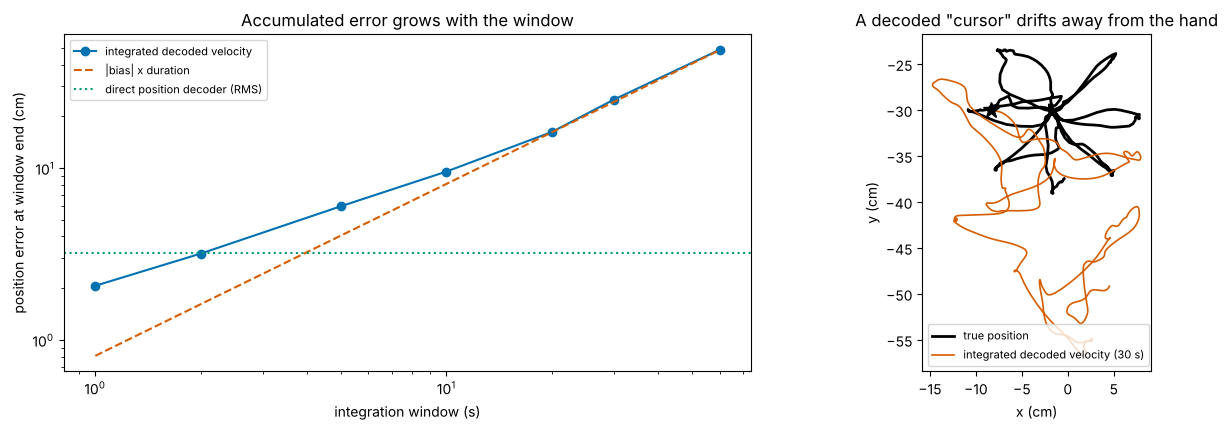

In [14]:
rates = m1['spikes'].T.astype(float) / 0.05                          # (15536, 171) spikes/s
X_dec = gaussian_filter1d(rates, 2, axis=0)[:-2]                      # (15534, 171) smoothed rates
V_t, P_t, T_t = vel[2:], pos[2:], time_s[2:]                          # velocity, position and time 100 ms later
n_t = len(X_dec); train = np.arange(n_t) < n_t // 2
D_dec = np.column_stack([np.ones(n_t), X_dec])
B_dec = np.linalg.lstsq(D_dec[train], V_t[train], rcond=None)[0]    # (172, 2) decoder weights
V_hat = D_dec @ B_dec                                                 # (15534, 2) decoded velocity, cm/s
resid = V_hat[~train] - V_t[~train]
r2_dec = 1 - np.sum(resid**2, axis=0) / np.sum((V_t[~train] - V_t[~train].mean(axis=0))**2, axis=0)
bias = resid.mean(axis=0)
print(f"decoder test R^2 (vx, vy) = {np.round(r2_dec, 3)};  mean decoding error on the test half (bias) = {np.round(bias, 3)} cm/s, |bias| = {np.linalg.norm(bias):.3f} cm/s")

test_idx = np.where(~train)[0]
win_s = np.array([1, 2, 5, 10, 20, 30, 60])                           # window lengths, s
med_err = []
for Ws in win_s:
    L_ = int(Ws / 0.05); errs_w = []
    for s in range(test_idx[0], test_idx[-1] - L_, L_):
        sl = slice(s, s + L_)
        p_hat_end = P_t[s] + np.trapezoid(V_hat[sl], T_t[sl], axis=0)
        errs_w.append(np.linalg.norm(p_hat_end - P_t[s + L_ - 1]))
    med_err.append(np.median(errs_w))
med_err = np.array(med_err)
for Ws, e in zip(win_s, med_err):
    print(f"window {Ws:3d} s: median end-of-window position error {e:6.2f} cm   (|bias| x duration = {np.linalg.norm(bias) * Ws:6.2f} cm)")

B_pos = np.linalg.lstsq(D_dec[train], P_t[train], rcond=None)[0]     # a decoder of position itself, for comparison
rms_pos = rms_cm(D_dec[~train] @ B_pos, P_t[~train])
print(f"decoding position directly: RMS error {rms_pos:.2f} cm on the test half (position SD {P_t[~train].std(axis=0).round(2)} cm)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].loglog(win_s, med_err, 'o-', color=PALETTE[0], label='integrated decoded velocity')
axes[0].loglog(win_s, np.linalg.norm(bias) * win_s, '--', color=PALETTE[1], label='|bias| x duration')
axes[0].axhline(rms_pos, color=PALETTE[2], ls=':', label='direct position decoder (RMS)')
axes[0].set_xlabel('integration window (s)'); axes[0].set_ylabel('position error at window end (cm)'); axes[0].set_title('Accumulated error grows with the window'); axes[0].legend(fontsize=8)
s = test_idx[0] + 200; sl = slice(s, s + 600)
p_dec = P_t[s] + cumulative_trapezoid(V_hat[sl], T_t[sl], axis=0, initial=0)
axes[1].plot(P_t[sl, 0], P_t[sl, 1], color='black', lw=2, label='true position')
axes[1].plot(p_dec[:, 0], p_dec[:, 1], color=PALETTE[1], lw=1.2, label='integrated decoded velocity (30 s)')
axes[1].plot(*P_t[s], 'k*', ms=12)
axes[1].set_aspect('equal'); axes[1].set_xlabel('x (cm)'); axes[1].set_ylabel('y (cm)'); axes[1].set_title('A decoded "cursor" drifts away from the hand'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**
- **The decoder is good moment to moment** (test $R^2$ about 0.76 and 0.60), and its average error on the test half is small: about 0.8 cm/s, against velocities of tens of cm/s.
- **Integration turns that small bias into a large error.** Over windows of a minute, the position error grows almost exactly as $|\text{bias}| \times \text{duration}$, reaching tens of centimetres, larger than the whole workspace.
- **Short windows behave differently.** Over a second or two the error is dominated by moment-to-moment fluctuations, which partly cancel when integrated, so the error is larger than the bias line but grows more slowly.
- **The bias comes from non-stationarity.** On the training half the decoder's errors average exactly zero (least squares guarantees this when there is an intercept). On the test half the neurons' baselines have drifted (Lesson 8), so the same weights produce a small systematic offset.
- **Decoding position directly** does not accumulate errors (RMS about 3 cm). Brain–computer interfaces that integrate velocity need the user in the loop to correct the drift, or periodic re-centring and recalibration.

**Limitations.** One session and one linear decoder; the decoder was fitted to recorded (not intended) movements; median errors over non-overlapping windows; the bias estimate uses the whole test half.

# **Part 6: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning / statistics |
|---|---|---|
| Integral of a rate | expected spike count $\int r\,dt$; PSTH area; total charge $\int I\,dt$ | expected counts in Poisson models (Lesson 18) |
| Accumulation function | membrane voltage integrates current ($C\,dV/dt = I$, Lesson 21); evidence accumulation in decision making (drift–diffusion) | cumulative sums; running averages; optimisers accumulate gradients (Lesson 12) |
| Average value | mean firing rate over a trial; time-averaged power | expectations $\mathbb{E}[X] = \int x\,p(x)\,dx$ (Lesson 17) |
| Signed area | net charge of inward and outward currents | — |
| Quadrature and sampling | integrating sampled signals (LFP power, calcium traces); dead reckoning from velocity | numerical integration of densities, normalising constants (Lesson 19) |
| Bias accumulates, noise averages | drift of integrated decoders; path integration by grid cells needs landmarks to correct drift | error accumulation in integrating ODE solvers (Lesson 21) |
| Irregular sampling | spike times, behavioural events, dropped frames | irregular time series; trapezoid rule on non-uniform grids |

**Path integration in the brain.** Animals estimate where they are by integrating their own movement (self-motion cues): a biological version of this mini-lab. Errors accumulate in exactly the way shown above, which is why grid-cell maps in entorhinal cortex are continuously re-anchored by landmarks and boundaries.

**Evidence accumulation.** In decision-making tasks, neurons in parietal cortex appear to integrate noisy sensory evidence over time until a bound is reached (the drift–diffusion model): the integral averages away noise, so decisions become more accurate with longer viewing.

# **Part 7: Summary and Lesson 14 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Antiderivative | $F' = f$; $\int f\,dx = F + C$ | fixed up to a constant |
| Definite integral | $\int_a^b f\,dx$ = signed area | units: [f] × [x] |
| Riemann sum | $\sum f(x_i^\star)\,h$ | the definition; left/right error $\propto h$, midpoint $\propto h^2$ |
| Average value | $\frac{1}{b - a}\int_a^b f$ | mean rate, mean current |
| Fundamental Theorem | $\frac{d}{dx}\int_a^x f = f$; $\int_a^b F' = F(b) - F(a)$ | accumulation and rate undo each other; `cumsum`/`diff` |
| Trapezoid / Simpson | `np.trapezoid(f, t)`, `simpson(f, x=t)` | error $\propto h^2$ / $h^4$ for smooth $f$ |
| Sampling interval | fixed by the data | limits accuracy; aliasing beyond the Nyquist limit |
| Noise vs bias | noise grows $\propto\sqrt T$, bias $\propto T$ | integrating decoders drift |
| Irregular sampling | trapezoid with the true times | never assume regular spacing |

**Lesson 14 — Multivariable gradients.** So far every function had one input. A loss usually depends on many parameters, a firing rate on several stimulus features. Lesson 14 introduces partial derivatives, the gradient vector, contour maps and the Hessian, the multivariable versions of Lessons 9–11.